# 07 — Frozen-model explainability

This notebook explains the models selected in notebook 05 and evaluated in notebook 06. It does not tune models, choose features, change calibration, or revise thresholds.

The explanation protocol is intentionally separated from final evaluation:

- coefficient direction and standardized magnitude for the 5-second logistic model;
- repeated validation-set permutation importance for the 30- and 60-second random forests;
- joint permutation of order state, LOB snapshot, and recent flow/activity groups;
- descriptive validation response profiles for leading numeric features;
- deterministic case studies drawn from the already-committed final-test predictions.


## Interpretation boundaries

Permutation importance measures the decrease in validation PR-AUC when a feature is shuffled. Correlated LOB variables can share or mask importance, so individual values are not additive. Logistic coefficients describe associations conditional on the included variables; they are not causal effects. Case studies are descriptive and do not feed back into model selection.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, brier_score_loss

RANDOM_SEED = 42
HORIZONS = (5, 30, 60)
PERMUTATION_REPEATS = 20
GROUP_PERMUTATION_REPEATS = 50

project_root_override = os.environ.get("LIMIT_ORDER_PROJECT_ROOT")
PROJECT_ROOT = Path(project_root_override) if project_root_override else Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = Path(os.environ.get("LIMIT_ORDER_ARTIFACT_DIR", PROJECT_ROOT / "results"))
FIGURE_DIR = Path(os.environ.get("LIMIT_ORDER_FIGURE_DIR", PROJECT_ROOT / "reports" / "figures"))
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from evaluation import (
    apply_sigmoid_calibrator,
    build_estimator,
    fit_sigmoid_calibrator,
)
from explainability import (
    FEATURE_GROUPS,
    feature_group,
    grouped_permutation_importance,
    logistic_categorical_contrasts,
    individual_permutation_importance,
    logistic_coefficient_table,
)
from modeling import (
    CATEGORICAL_FEATURES,
    FEATURE_SETS,
    add_oriented_static_features,
)

POLICY_PATH = PROJECT_ROOT / "results" / "selected_model_policy.json"
FINAL_SUMMARY_PATH = PROJECT_ROOT / "results" / "final_test_summary.json"
FINAL_PREDICTIONS_PATH = PROJECT_ROOT / "results" / "final_test_predictions.csv"

policy_bytes = POLICY_PATH.read_bytes()
policy = json.loads(policy_bytes)
final_summary = json.loads(FINAL_SUMMARY_PATH.read_text())
final_test_predictions = pd.read_csv(FINAL_PREDICTIONS_PATH)
policy_sha256 = hashlib.sha256(policy_bytes).hexdigest()
analysis_source_commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, text=True
).strip()
workspace_status = subprocess.check_output(
    ["git", "status", "--porcelain"], cwd=PROJECT_ROOT, text=True
).strip()

assert workspace_status == "", "Worktree must be clean before explainability analysis."
assert policy["status"] == "validation_selected_test_not_evaluated"
assert final_summary["status"] == "final_test_evaluated"
assert final_summary["frozen_policy_sha256"] == policy_sha256
assert set(final_test_predictions["horizon_seconds"]) == set(HORIZONS)

print("Analysis source commit:", analysis_source_commit)
print("Frozen policy SHA-256:", policy_sha256)
print("Final test predictions reused from notebook 06:", len(final_test_predictions))
print("Raw test target columns requested in this notebook: 0")


Analysis source commit: bb356563c784d29795c014c6c4931c3982e3008b
Frozen policy SHA-256: 92a6631d142c8cd493898b9c1934ebed4ac553b9dc41e189b4323b2d60a3f78d
Final test predictions reused from notebook 06: 4005
Raw test target columns requested in this notebook: 0


## Development data and frozen model reconstruction

Only the first 8,500 chronological workbook rows are read for training and validation. The 1,500 raw test rows are not loaded with target columns. Later case studies reuse the predictions already saved by notebook 06 and load only their non-outcome feature values.


In [2]:
excel_files = sorted(RAW_DIR.glob("*.xlsx"))
assert len(excel_files) == 1
EXCEL_PATH = excel_files[0]

development = pd.read_excel(EXCEL_PATH, sheet_name="Orders", nrows=8_500)
development["data_split_normalized"] = development["data_split"].astype(str).str.lower()
development["trading_day_parsed"] = pd.to_datetime(development["trading_day"])

assert len(development) == 8_500
assert development["order_id"].is_unique
assert development["data_split_normalized"].value_counts().to_dict() == {
    "train": 7_000,
    "validation": 1_500,
}
assert not development["data_split_normalized"].eq("test").any()

development = add_oriented_static_features(development)
training_rows = development.loc[development["data_split_normalized"].eq("train")].copy()
validation_rows = development.loc[development["data_split_normalized"].eq("validation")].copy()

selected_feature_sets = {
    policy["horizons"][str(horizon)]["feature_set"] for horizon in HORIZONS
}
assert selected_feature_sets <= {"B_order_lob", "C_order_lob_flow"}
for feature_set_name in selected_feature_sets:
    assert development[FEATURE_SETS[feature_set_name]].notna().all().all()

training_days = sorted(training_rows["trading_day_parsed"].unique())
assert len(training_days) == 14
fold_day_specs = [
    (training_days[:6], training_days[6:8]),
    (training_days[:8], training_days[8:10]),
    (training_days[:10], training_days[10:12]),
    (training_days[:12], training_days[12:14]),
]

print("Development rows:", len(development))
print("Training / validation:", len(training_rows), len(validation_rows))
print("Selected feature sets:", sorted(selected_feature_sets))


Development rows: 8500
Training / validation: 7000 1500
Selected feature sets: ['B_order_lob', 'C_order_lob_flow']


In [3]:
fitted_estimators = {}
fitted_calibrators = {}
validation_prediction_frames = {}
reproduction_rows = []

for horizon in HORIZONS:
    horizon_policy = policy["horizons"][str(horizon)]
    feature_set_name = horizon_policy["feature_set"]
    model_name = horizon_policy["model"]
    parameters = horizon_policy["parameters"]
    features = FEATURE_SETS[feature_set_name]
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"

    oof_probabilities = []
    oof_targets = []
    for fit_days, score_days in fold_day_specs:
        fit_mask = training_rows["trading_day_parsed"].isin(fit_days) & training_rows[eligibility].eq(1)
        score_mask = training_rows["trading_day_parsed"].isin(score_days) & training_rows[eligibility].eq(1)
        fold_estimator = build_estimator(
            feature_set_name,
            model_name,
            parameters,
            random_seed=RANDOM_SEED,
        )
        fold_estimator.fit(
            training_rows.loc[fit_mask, features],
            training_rows.loc[fit_mask, target].astype(int),
        )
        oof_probabilities.append(
            fold_estimator.predict_proba(training_rows.loc[score_mask, features])[:, 1]
        )
        oof_targets.append(training_rows.loc[score_mask, target].astype(int).to_numpy())

    calibrator = fit_sigmoid_calibrator(
        np.concatenate(oof_probabilities),
        np.concatenate(oof_targets),
    )
    train_mask = training_rows[eligibility].eq(1)
    validation_mask = validation_rows[eligibility].eq(1)
    estimator = build_estimator(
        feature_set_name,
        model_name,
        parameters,
        random_seed=RANDOM_SEED,
    )
    estimator.fit(
        training_rows.loc[train_mask, features],
        training_rows.loc[train_mask, target].astype(int),
    )

    raw_probability = estimator.predict_proba(
        validation_rows.loc[validation_mask, features]
    )[:, 1]
    calibrated_probability = apply_sigmoid_calibrator(calibrator, raw_probability)
    y_validation = validation_rows.loc[validation_mask, target].astype(int).to_numpy()
    reproduced_pr_auc = average_precision_score(y_validation, calibrated_probability)
    reproduced_brier = brier_score_loss(y_validation, calibrated_probability)

    expected_metrics = horizon_policy["validation_metrics"]
    assert np.isclose(reproduced_pr_auc, expected_metrics["pr_auc"], atol=1e-12)
    assert np.isclose(reproduced_brier, expected_metrics["brier_score"], atol=1e-12)

    fitted_estimators[horizon] = estimator
    fitted_calibrators[horizon] = calibrator
    validation_prediction_frames[horizon] = validation_rows.loc[validation_mask].copy()
    validation_prediction_frames[horizon]["target_fill"] = y_validation
    validation_prediction_frames[horizon]["raw_probability"] = raw_probability
    validation_prediction_frames[horizon]["calibrated_probability"] = calibrated_probability
    reproduction_rows.append({
        "horizon_seconds": horizon,
        "candidate": horizon_policy["candidate"],
        "eligible_validation_rows": int(validation_mask.sum()),
        "reproduced_pr_auc": float(reproduced_pr_auc),
        "policy_pr_auc": float(expected_metrics["pr_auc"]),
        "reproduced_brier_score": float(reproduced_brier),
        "policy_brier_score": float(expected_metrics["brier_score"]),
    })

reproduction_check = pd.DataFrame(reproduction_rows)
display(reproduction_check.round(6))


,horizon_seconds,candidate,eligible_validation_rows,reproduced_pr_auc,policy_pr_auc,reproduced_brier_score,policy_brier_score
0,5,B_logistic,1455,0.246622,0.246622,0.087183,0.087183
1,30,C_random_forest,1324,0.604296,0.604296,0.213757,0.213757
2,60,C_random_forest,1241,0.797572,0.797572,0.210837,0.210837


## 5-second logistic model

Numeric variables were standardized before fitting, so each numeric coefficient is the log-odds association for a one-standard-deviation increase. Because the fitted pipeline uses full one-hot encoding, categorical variables are reported as within-feature coefficient contrasts rather than raw dummy coefficients.


Largest positive numeric coefficients


,display_feature,feature_type,feature_group,coefficient,odds_ratio
5,queue_ahead_qty,numeric_standardized,order_state,0.3089,1.3620
33,same_side_depth_5,numeric_standardized,lob_snapshot,0.1375,1.1474
27,ask_volume_l5,numeric_standardized,lob_snapshot,0.1220,1.1298
2,order_size,numeric_standardized,order_state,0.0839,1.0876
15,ask_volume_l2,numeric_standardized,lob_snapshot,0.0601,1.0620
21,bid_volume_l4,numeric_standardized,lob_snapshot,0.0517,1.0530
0,seconds_from_open,numeric_standardized,order_state,0.0495,1.0508
25,bid_volume_l5,numeric_standardized,lob_snapshot,0.0446,1.0456
19,ask_volume_l3,numeric_standardized,lob_snapshot,0.0308,1.0313
30,relative_spread_bps,numeric_standardized,lob_snapshot,0.0146,1.0147


Largest negative numeric coefficients


,display_feature,feature_type,feature_group,coefficient,odds_ratio
3,price_distance_ticks,numeric_standardized,order_state,-0.5776,0.5612
6,same_price_total_qty,numeric_standardized,order_state,-0.3282,0.7202
7,normalized_queue_ahead,numeric_standardized,order_state,-0.2400,0.7866
32,five_level_side_imbalance,numeric_standardized,lob_snapshot,-0.2114,0.8094
31,oriented_top_level_imbalance,numeric_standardized,lob_snapshot,-0.1744,0.8400
11,ask_volume_l1,numeric_standardized,lob_snapshot,-0.1110,0.8950
34,opposite_side_depth_5,numeric_standardized,lob_snapshot,-0.1002,0.9046
23,ask_volume_l4,numeric_standardized,lob_snapshot,-0.0385,0.9622
9,bid_volume_l1,numeric_standardized,lob_snapshot,-0.0369,0.9638
17,bid_volume_l3,numeric_standardized,lob_snapshot,-0.0336,0.9669


Categorical within-feature contrasts


,original_feature,comparison_level,reference_level,contrast_label,log_odds_contrast,odds_ratio_contrast,direction
0,side,sell,buy,side: sell vs buy,-0.0013,0.9987,lower_fill_probability
2,session_phase,closing,continuous,session_phase: closing vs continuous,-0.0673,0.9349,lower_fill_probability
1,session_phase,opening,continuous,session_phase: opening vs continuous,-0.0827,0.9206,lower_fill_probability


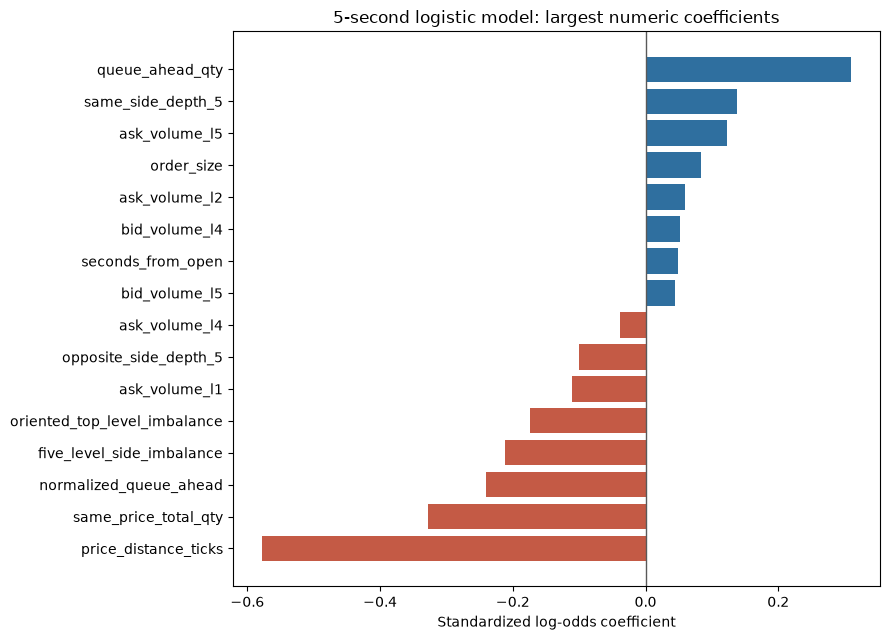

In [4]:
logistic_coefficients = logistic_coefficient_table(fitted_estimators[5])
logistic_numeric_coefficients = logistic_coefficients.loc[
    logistic_coefficients["feature_type"].eq("numeric_standardized")
].copy()
logistic_categorical_contrast_table = logistic_categorical_contrasts(
    logistic_coefficients,
    reference_levels={"side": "buy", "session_phase": "continuous"},
)

print("Largest positive numeric coefficients")
display(
    logistic_numeric_coefficients.sort_values("coefficient", ascending=False)[
        ["display_feature", "feature_type", "feature_group", "coefficient", "odds_ratio"]
    ].head(10).round(4)
)
print("Largest negative numeric coefficients")
display(
    logistic_numeric_coefficients.sort_values("coefficient", ascending=True)[
        ["display_feature", "feature_type", "feature_group", "coefficient", "odds_ratio"]
    ].head(10).round(4)
)
print("Categorical within-feature contrasts")
display(logistic_categorical_contrast_table.round(4))

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
coefficient_plot = logistic_numeric_coefficients.head(16).sort_values("coefficient")
fig, ax = plt.subplots(figsize=(9, 6.5))
colors = np.where(coefficient_plot["coefficient"].ge(0), "#2f6f9f", "#c45a45")
ax.barh(coefficient_plot["display_feature"], coefficient_plot["coefficient"], color=colors)
ax.axvline(0, color="0.35", linewidth=1)
ax.set_xlabel("Standardized log-odds coefficient")
ax.set_title("5-second logistic model: largest numeric coefficients")
fig.tight_layout()
coefficient_figure_path = FIGURE_DIR / "explainability_logistic_coefficients_5s.png"
fig.savefig(coefficient_figure_path, dpi=180, bbox_inches="tight")
plt.show()


## Random-forest permutation importance

Each original feature is independently shuffled on the official validation rows. Importance is the decrease in PR-AUC relative to the unchanged frozen estimator. Calibration is monotonic sigmoid scaling, so it does not change probability ranking or PR-AUC.



30s top validation permutation importances


,horizon_seconds,feature,feature_group,pr_auc_decrease_mean,pr_auc_decrease_std,pr_auc_decrease_ci_low,pr_auc_decrease_ci_high,repeats
5,30,queue_ahead_qty,order_state,0.06087,0.01069,0.04266,0.07772,20
7,30,normalized_queue_ahead,order_state,0.04420,0.00730,0.03166,0.05645,20
44,30,aggressive_trade_volume_against_order_10s,recent_flow_activity,0.03980,0.01013,0.02357,0.05644,20
3,30,price_distance_ticks,order_state,0.01739,0.00551,0.00756,0.02655,20
34,30,five_level_side_imbalance,lob_snapshot,0.00518,0.00281,-0.00010,0.00922,20
36,30,opposite_side_depth_5,lob_snapshot,0.00208,0.00119,0.00021,0.00380,20
33,30,oriented_top_level_imbalance,lob_snapshot,0.00163,0.00178,-0.00064,0.00551,20
23,30,bid_volume_l4,lob_snapshot,0.00153,0.00093,-0.00005,0.00305,20
6,30,same_price_total_qty,order_state,0.00113,0.00229,-0.00209,0.00514,20
47,30,time_since_last_trade_ms,recent_flow_activity,0.00060,0.00131,-0.00150,0.00303,20



60s top validation permutation importances


,horizon_seconds,feature,feature_group,pr_auc_decrease_mean,pr_auc_decrease_std,pr_auc_decrease_ci_low,pr_auc_decrease_ci_high,repeats
5,60,queue_ahead_qty,order_state,0.04240,0.00796,0.03006,0.05893,20
44,60,aggressive_trade_volume_against_order_10s,recent_flow_activity,0.03033,0.00685,0.01826,0.04044,20
7,60,normalized_queue_ahead,order_state,0.02928,0.00430,0.02296,0.03625,20
3,60,price_distance_ticks,order_state,0.02101,0.00409,0.01486,0.02830,20
34,60,five_level_side_imbalance,lob_snapshot,0.00411,0.00269,0.00079,0.00991,20
36,60,opposite_side_depth_5,lob_snapshot,0.00261,0.00185,0.00055,0.00628,20
46,60,trade_count_10s,recent_flow_activity,0.00232,0.00254,-0.00134,0.00682,20
21,60,ask_volume_l3,lob_snapshot,0.00185,0.00104,0.00032,0.00357,20
33,60,oriented_top_level_imbalance,lob_snapshot,0.00174,0.00140,-0.00033,0.00408,20
2,60,order_size,order_state,0.00110,0.00076,-0.00011,0.00217,20


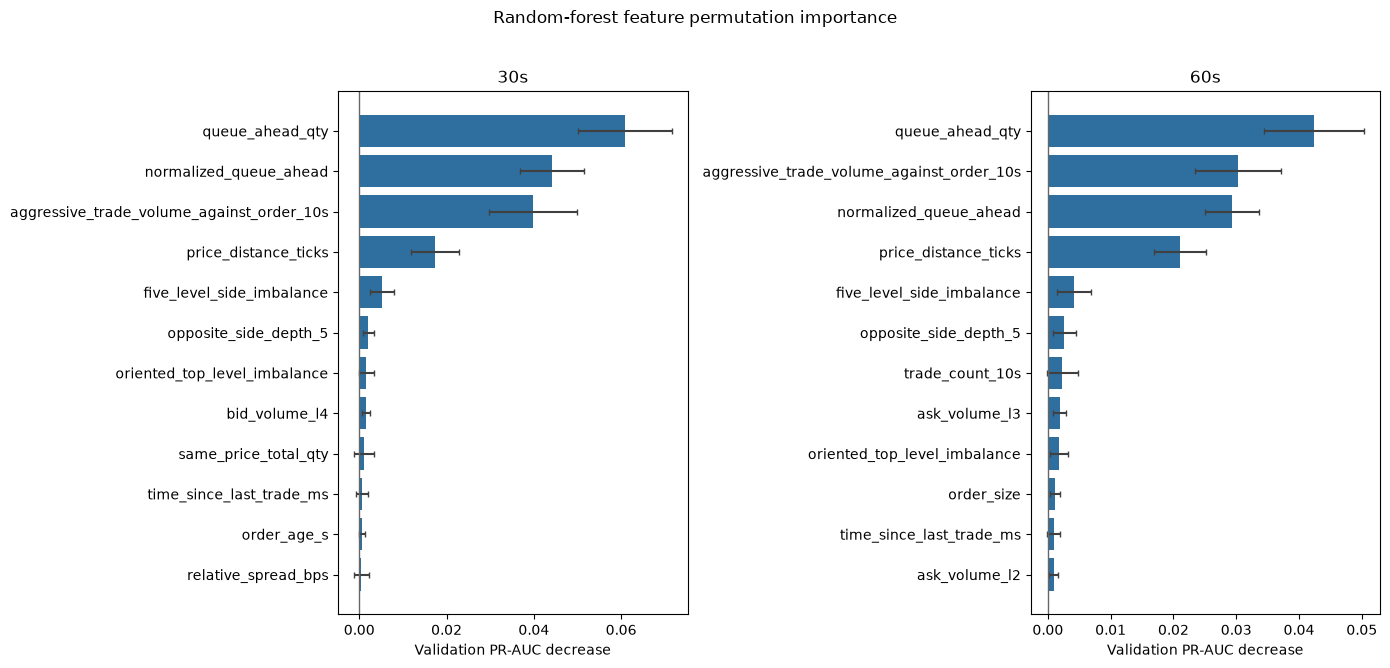

In [5]:
permutation_tables = {}
for horizon in (30, 60):
    horizon_policy = policy["horizons"][str(horizon)]
    features = FEATURE_SETS[horizon_policy["feature_set"]]
    frame = validation_prediction_frames[horizon]
    table = individual_permutation_importance(
        fitted_estimators[horizon],
        frame,
        frame["target_fill"].astype(int),
        features,
        random_seed=RANDOM_SEED + horizon,
        repeats=PERMUTATION_REPEATS,
    )
    table.insert(0, "horizon_seconds", horizon)
    permutation_tables[horizon] = table
    print()
    print(f"{horizon}s top validation permutation importances")
    display(table.head(12).round(5))

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, horizon in zip(axes, (30, 60)):
    top = permutation_tables[horizon].head(12).sort_values("pr_auc_decrease_mean")
    ax.barh(top["feature"], top["pr_auc_decrease_mean"], color="#2f6f9f")
    ax.errorbar(
        top["pr_auc_decrease_mean"],
        np.arange(len(top)),
        xerr=top["pr_auc_decrease_std"],
        fmt="none",
        ecolor="0.25",
        capsize=2,
    )
    ax.axvline(0, color="0.4", linewidth=1)
    ax.set_title(f"{horizon}s")
    ax.set_xlabel("Validation PR-AUC decrease")

fig.suptitle("Random-forest feature permutation importance", y=1.02)
fig.tight_layout()
permutation_figure_path = FIGURE_DIR / "explainability_permutation_importance_rf.png"
fig.savefig(permutation_figure_path, dpi=180, bbox_inches="tight")
plt.show()


## Signal source by feature group

Related variables are permuted together using the same row permutation within each group. This better reflects the total information carried by correlated LOB levels or flow measures, although overlapping information across groups can still make the decreases non-additive.


,horizon_seconds,feature_group,feature_count,baseline_pr_auc,pr_auc_decrease_mean,pr_auc_decrease_std,pr_auc_decrease_ci_low,pr_auc_decrease_ci_high,repeats
0,5,order_state,10,0.24662,0.11626,0.00850,0.10093,0.13168,50
1,5,lob_snapshot,29,0.24662,0.05837,0.01726,0.02064,0.08595,50
2,30,order_state,10,0.60430,0.16972,0.01430,0.14308,0.19631,50
3,30,recent_flow_activity,10,0.60430,0.04107,0.00903,0.02704,0.05916,50
4,30,lob_snapshot,29,0.60430,0.00818,0.00579,-0.00168,0.02004,50
5,60,order_state,10,0.79757,0.13827,0.01408,0.11212,0.16108,50
6,60,recent_flow_activity,10,0.79757,0.04093,0.00805,0.02311,0.05370,50
7,60,lob_snapshot,29,0.79757,0.01495,0.00469,0.00606,0.02485,50


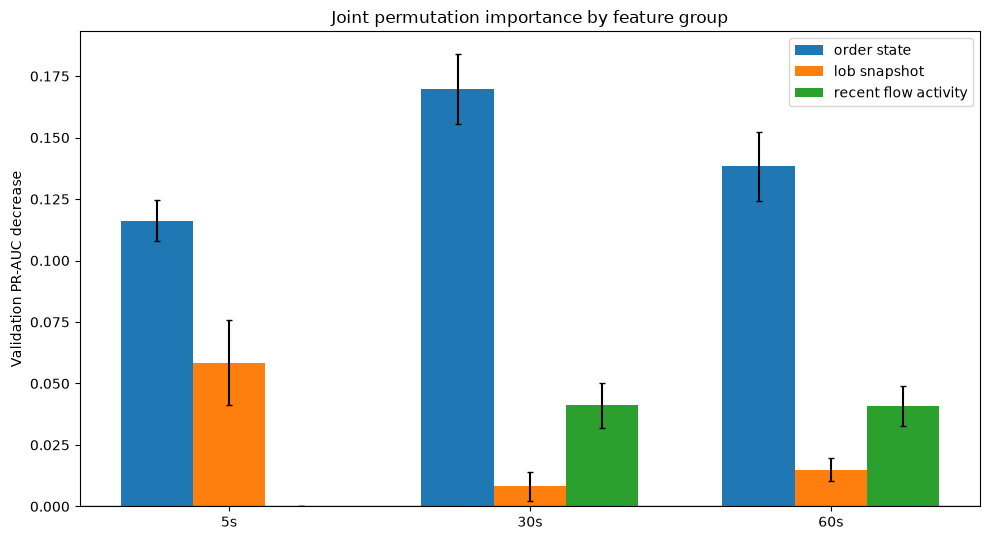

In [6]:
group_tables = []
for horizon in HORIZONS:
    horizon_policy = policy["horizons"][str(horizon)]
    features = FEATURE_SETS[horizon_policy["feature_set"]]
    frame = validation_prediction_frames[horizon]
    table = grouped_permutation_importance(
        fitted_estimators[horizon],
        frame,
        frame["target_fill"].astype(int),
        features,
        random_seed=RANDOM_SEED + 100 + horizon,
        repeats=GROUP_PERMUTATION_REPEATS,
    )
    table.insert(0, "horizon_seconds", horizon)
    group_tables.append(table)

grouped_importance = pd.concat(group_tables, ignore_index=True)
display(grouped_importance.round(5))

group_order = ["order_state", "lob_snapshot", "recent_flow_activity"]
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(HORIZONS))
width = 0.24
for offset, group_name in enumerate(group_order):
    values = []
    errors = []
    for horizon in HORIZONS:
        match = grouped_importance.loc[
            grouped_importance["horizon_seconds"].eq(horizon)
            & grouped_importance["feature_group"].eq(group_name)
        ]
        values.append(float(match["pr_auc_decrease_mean"].iloc[0]) if len(match) else 0.0)
        errors.append(float(match["pr_auc_decrease_std"].iloc[0]) if len(match) else 0.0)
    ax.bar(
        x + (offset - 1) * width,
        values,
        width,
        yerr=errors,
        capsize=2,
        label=group_name.replace("_", " "),
    )

ax.set_xticks(x, [f"{horizon}s" for horizon in HORIZONS])
ax.set_ylabel("Validation PR-AUC decrease")
ax.set_title("Joint permutation importance by feature group")
ax.axhline(0, color="0.4", linewidth=1)
ax.legend()
fig.tight_layout()
group_figure_path = FIGURE_DIR / "explainability_group_importance.png"
fig.savefig(group_figure_path, dpi=180, bbox_inches="tight")
plt.show()


## Validation response profiles

For the two leading numeric features at each horizon, validation rows are divided into quantile bins. The lines show the observed fill rate and the model's mean calibrated probability. These are descriptive conditional profiles, not partial causal effects.


,horizon_seconds,feature,feature_group,quantile_bin,rows,feature_min,feature_median,feature_max,observed_fill_rate,mean_predicted_probability
0,5,price_distance_ticks,order_state,1,1308,0.00000,0.00000,1.00000,0.10856,0.11506
1,5,price_distance_ticks,order_state,2,147,2.00000,2.00000,4.00000,0.04762,0.02618
2,5,same_price_total_qty,order_state,1,182,21.00000,59.50000,239.00000,0.20879,0.16289
3,5,same_price_total_qty,order_state,2,182,240.00000,379.50000,517.00000,0.12637,0.14100
4,5,same_price_total_qty,order_state,3,182,518.00000,660.00000,773.00000,0.11538,0.11398
5,5,same_price_total_qty,order_state,4,182,777.00000,926.00000,1076.00000,0.10440,0.10345
6,5,same_price_total_qty,order_state,5,181,1077.00000,1206.00000,1372.00000,0.08287,0.09685
7,5,same_price_total_qty,order_state,6,182,1373.00000,1563.50000,1785.00000,0.07692,0.08469
8,5,same_price_total_qty,order_state,7,182,1788.00000,2051.00000,2422.00000,0.04396,0.07659
9,5,same_price_total_qty,order_state,8,182,2436.00000,2944.50000,7711.00000,0.06044,0.06915


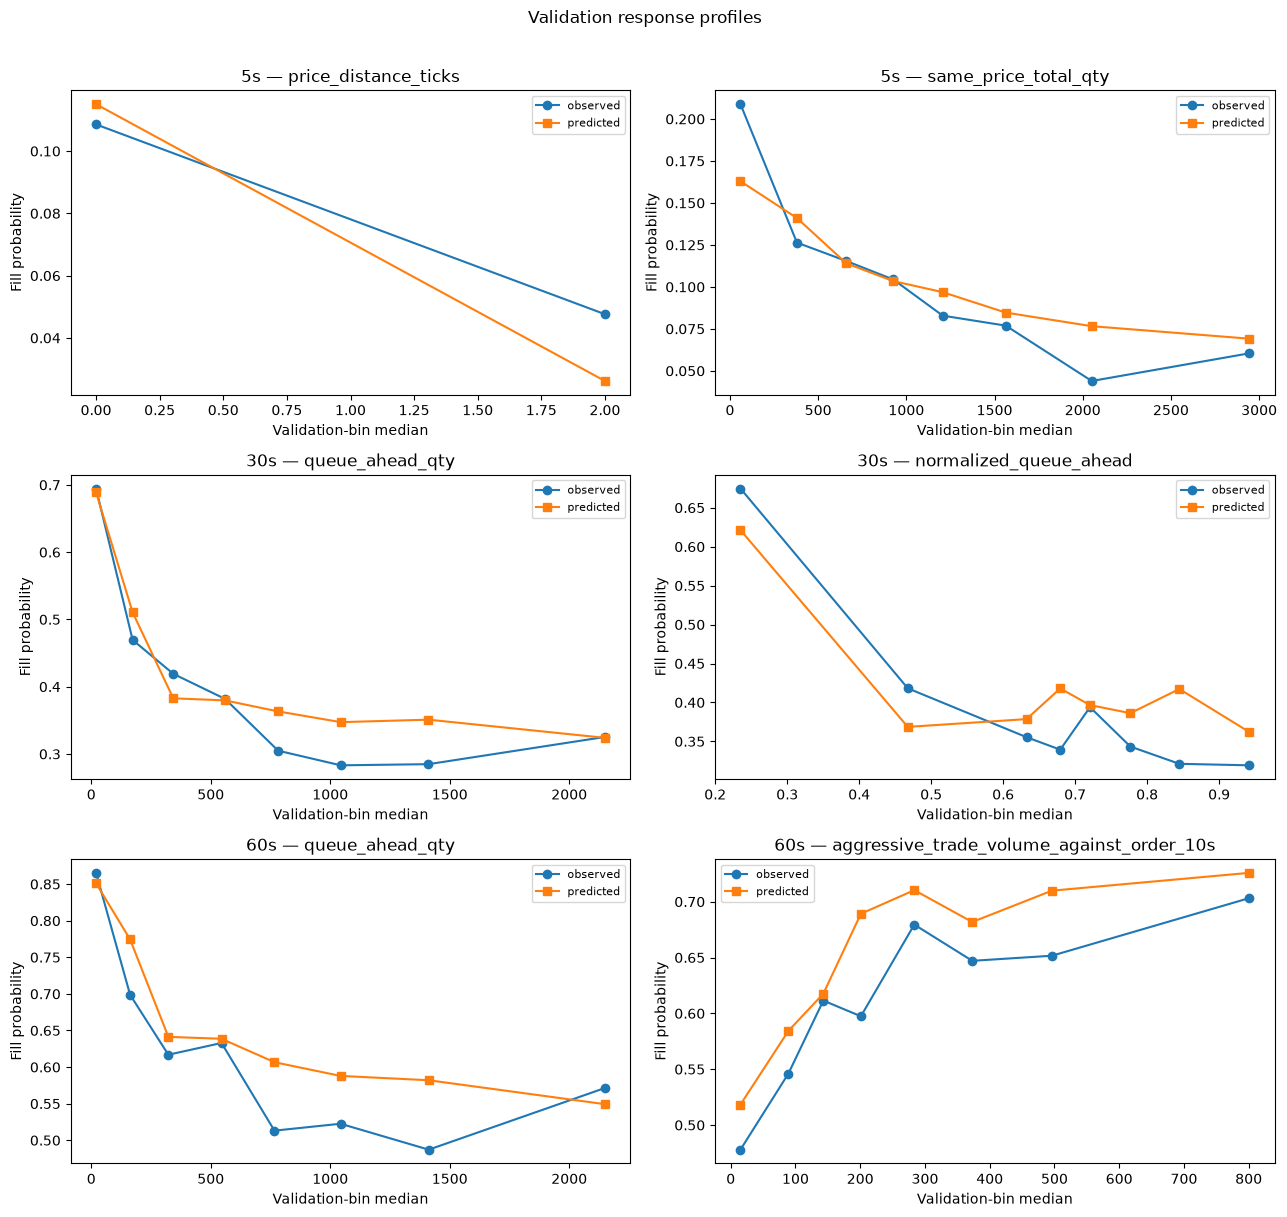

In [7]:
top_numeric_features = {}

numeric_5s = logistic_coefficients.loc[
    logistic_coefficients["feature_type"].eq("numeric_standardized")
].drop_duplicates("original_feature")
top_numeric_features[5] = numeric_5s.head(2)["original_feature"].tolist()

for horizon in (30, 60):
    numeric_table = permutation_tables[horizon].loc[
        ~permutation_tables[horizon]["feature"].isin(CATEGORICAL_FEATURES)
    ]
    top_numeric_features[horizon] = numeric_table.head(2)["feature"].tolist()

profile_rows = []
for horizon in HORIZONS:
    frame = validation_prediction_frames[horizon].copy()
    for feature in top_numeric_features[horizon]:
        bins = pd.qcut(frame[feature], q=8, duplicates="drop")
        temporary = pd.DataFrame({
            "bin": bins,
            "feature_value": frame[feature],
            "target_fill": frame["target_fill"],
            "calibrated_probability": frame["calibrated_probability"],
        })
        grouped = temporary.groupby("bin", observed=True, sort=True)
        for bin_number, (_, group) in enumerate(grouped, start=1):
            profile_rows.append({
                "horizon_seconds": horizon,
                "feature": feature,
                "feature_group": feature_group(feature),
                "quantile_bin": bin_number,
                "rows": int(len(group)),
                "feature_min": float(group["feature_value"].min()),
                "feature_median": float(group["feature_value"].median()),
                "feature_max": float(group["feature_value"].max()),
                "observed_fill_rate": float(group["target_fill"].mean()),
                "mean_predicted_probability": float(group["calibrated_probability"].mean()),
            })

response_profiles = pd.DataFrame(profile_rows)
display(response_profiles.round(5))

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for row_number, horizon in enumerate(HORIZONS):
    for column_number, feature in enumerate(top_numeric_features[horizon]):
        ax = axes[row_number, column_number]
        plot_data = response_profiles.loc[
            response_profiles["horizon_seconds"].eq(horizon)
            & response_profiles["feature"].eq(feature)
        ]
        ax.plot(
            plot_data["feature_median"],
            plot_data["observed_fill_rate"],
            marker="o",
            label="observed",
        )
        ax.plot(
            plot_data["feature_median"],
            plot_data["mean_predicted_probability"],
            marker="s",
            label="predicted",
        )
        ax.set_title(f"{horizon}s — {feature}")
        ax.set_xlabel("Validation-bin median")
        ax.set_ylabel("Fill probability")
        ax.legend(fontsize=8)

fig.suptitle("Validation response profiles", y=1.01)
fig.tight_layout()
response_figure_path = FIGURE_DIR / "explainability_response_profiles.png"
fig.savefig(response_figure_path, dpi=180, bbox_inches="tight")
plt.show()


## Frozen test-prediction case studies

Cases are chosen mechanically within each horizon: highest-probability true positive, highest-probability false positive, lowest-probability false negative, and the remaining order closest to the frozen threshold. Test outcomes come only from notebook 06's committed prediction artifact. The raw workbook is queried only for non-outcome feature values.


In [8]:
def select_case(group, condition, sort_column, ascending, excluded_order_ids):
    candidates = group.loc[condition & ~group["order_id"].isin(excluded_order_ids)]
    if candidates.empty:
        return None
    return candidates.sort_values(sort_column, ascending=ascending).iloc[0]


case_rows = []
for horizon in HORIZONS:
    group = final_test_predictions.loc[
        final_test_predictions["horizon_seconds"].eq(horizon)
    ].copy()
    group["distance_to_threshold"] = (
        group["calibrated_probability"] - group["selected_threshold"]
    ).abs()
    chosen_ids = set()
    case_specs = [
        (
            "highest_probability_true_positive",
            group["target_fill"].eq(1) & group["predicted_fill"].eq(1),
            "calibrated_probability",
            False,
        ),
        (
            "highest_probability_false_positive",
            group["target_fill"].eq(0) & group["predicted_fill"].eq(1),
            "calibrated_probability",
            False,
        ),
        (
            "lowest_probability_false_negative",
            group["target_fill"].eq(1) & group["predicted_fill"].eq(0),
            "calibrated_probability",
            True,
        ),
        (
            "closest_to_threshold",
            pd.Series(True, index=group.index),
            "distance_to_threshold",
            True,
        ),
    ]
    for case_type, condition, sort_column, ascending in case_specs:
        selected = select_case(group, condition, sort_column, ascending, chosen_ids)
        if selected is None:
            continue
        chosen_ids.add(selected["order_id"])
        case_rows.append({"case_type": case_type, **selected.to_dict()})

case_studies = pd.DataFrame(case_rows)
case_order_ids = set(case_studies["order_id"])

case_source_columns = {
    "order_id", "side", "session_phase", "market_activity_group", "top_level_imbalance"
}
for feature_set_name in selected_feature_sets:
    case_source_columns.update(
        feature for feature in FEATURE_SETS[feature_set_name]
        if feature != "oriented_top_level_imbalance"
    )
assert not any(column.startswith("target_") for column in case_source_columns)
assert not any(column.startswith("eligible_") for column in case_source_columns)

case_feature_source = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Orders",
    usecols=lambda column: column in case_source_columns,
)
case_feature_source = add_oriented_static_features(case_feature_source)
case_feature_source = case_feature_source.loc[
    case_feature_source["order_id"].isin(case_order_ids)
].copy()
assert len(case_feature_source) == len(case_order_ids)

case_studies = case_studies.merge(
    case_feature_source,
    on=["order_id", "side", "market_activity_group"],
    how="left",
    validate="many_to_one",
)

case_feature_rows = []
for case in case_studies.to_dict("records"):
    horizon = int(case["horizon_seconds"])
    if horizon == 5:
        feature_table = numeric_5s.rename(
            columns={"original_feature": "feature", "abs_coefficient": "importance_value"}
        )
        selected_features = feature_table[["feature", "importance_value"]].head(5).to_dict("records")
        importance_source = "absolute_standardized_coefficient"
    else:
        selected_features = permutation_tables[horizon][
            ["feature", "pr_auc_decrease_mean"]
        ].head(5).rename(
            columns={"pr_auc_decrease_mean": "importance_value"}
        ).to_dict("records")
        importance_source = "validation_pr_auc_permutation_decrease"

    eligibility = f"eligible_{horizon}s"
    training_reference = training_rows.loc[training_rows[eligibility].eq(1)]
    for selected_feature in selected_features:
        feature = selected_feature["feature"]
        value = case[feature]
        if feature in CATEGORICAL_FEATURES:
            percentile = np.nan
            category_frequency = float(training_reference[feature].eq(value).mean())
        else:
            percentile = float(training_reference[feature].le(value).mean())
            category_frequency = np.nan
        case_feature_rows.append({
            "horizon_seconds": horizon,
            "order_id": case["order_id"],
            "case_type": case["case_type"],
            "feature": feature,
            "feature_group": feature_group(feature),
            "raw_value": value,
            "training_percentile": percentile,
            "training_category_frequency": category_frequency,
            "importance_source": importance_source,
            "importance_value": float(selected_feature["importance_value"]),
        })

case_feature_details = pd.DataFrame(case_feature_rows)
display(
    case_studies[
        [
            "horizon_seconds", "case_type", "order_id", "side", "market_activity_group",
            "target_fill", "predicted_fill", "calibrated_probability",
            "selected_threshold", "distance_to_threshold",
        ]
    ].round(5)
)
display(case_feature_details.round(5))


,horizon_seconds,case_type,order_id,side,market_activity_group,target_fill,predicted_fill,calibrated_probability,selected_threshold,distance_to_threshold
0,5,highest_probability_true_positive,ORD008983,buy,medium,1,1,0.32207,0.18907,0.13300
1,5,highest_probability_false_positive,ORD008865,buy,low,0,1,0.42282,0.18907,0.23375
2,5,lowest_probability_false_negative,ORD009769,sell,medium,1,0,0.01845,0.18907,0.17061
3,5,closest_to_threshold,ORD009130,buy,medium,0,1,0.18916,0.18907,0.00009
4,30,highest_probability_true_positive,ORD009432,sell,medium,1,1,0.88910,0.34722,0.54188
5,30,highest_probability_false_positive,ORD009727,sell,medium,0,1,0.87658,0.34722,0.52935
6,30,lowest_probability_false_negative,ORD008767,buy,low,1,0,0.05990,0.34722,0.28733
7,30,closest_to_threshold,ORD009590,sell,low,0,1,0.34761,0.34722,0.00039
8,60,highest_probability_true_positive,ORD009599,buy,medium,1,1,0.97815,0.34344,0.63471
9,60,highest_probability_false_positive,ORD008684,buy,medium,0,1,0.96780,0.34344,0.62436


,horizon_seconds,order_id,case_type,feature,feature_group,raw_value,training_percentile,training_category_frequency,importance_source,importance_value
0,5,ORD008983,highest_probability_true_positive,price_distance_ticks,order_state,0.00000,0.77817,NaN,absolute_standardized_coefficient,0.57764
1,5,ORD008983,highest_probability_true_positive,same_price_total_qty,order_state,363.00000,0.16894,NaN,absolute_standardized_coefficient,0.32825
2,5,ORD008983,highest_probability_true_positive,queue_ahead_qty,order_state,72.00000,0.10004,NaN,absolute_standardized_coefficient,0.30893
3,5,ORD008983,highest_probability_true_positive,normalized_queue_ahead,order_state,0.19835,0.04819,NaN,absolute_standardized_coefficient,0.24003
4,5,ORD008983,highest_probability_true_positive,five_level_side_imbalance,lob_snapshot,-0.11709,0.18554,NaN,absolute_standardized_coefficient,0.21141
5,5,ORD008865,highest_probability_false_positive,price_distance_ticks,order_state,0.00000,0.77817,NaN,absolute_standardized_coefficient,0.57764
6,5,ORD008865,highest_probability_false_positive,same_price_total_qty,order_state,409.00000,0.19054,NaN,absolute_standardized_coefficient,0.32825
7,5,ORD008865,highest_probability_false_positive,queue_ahead_qty,order_state,11.00000,0.01263,NaN,absolute_standardized_coefficient,0.30893
8,5,ORD008865,highest_probability_false_positive,normalized_queue_ahead,order_state,0.02690,0.00485,NaN,absolute_standardized_coefficient,0.24003
9,5,ORD008865,highest_probability_false_positive,five_level_side_imbalance,lob_snapshot,-0.31466,0.00720,NaN,absolute_standardized_coefficient,0.21141


## Export explanation artifacts

These outputs document the frozen models. They are not inputs to a new selection round.


In [9]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

logistic_path = RESULTS_DIR / "logistic_coefficients_5s.csv"
logistic_contrasts_path = RESULTS_DIR / "logistic_categorical_contrasts_5s.csv"
permutation_30_path = RESULTS_DIR / "permutation_importance_30s.csv"
permutation_60_path = RESULTS_DIR / "permutation_importance_60s.csv"
group_path = RESULTS_DIR / "grouped_permutation_importance.csv"
profiles_path = RESULTS_DIR / "validation_response_profiles.csv"
cases_path = RESULTS_DIR / "explanation_case_studies.csv"
case_features_path = RESULTS_DIR / "explanation_case_features.csv"
reproduction_path = RESULTS_DIR / "explainability_reproduction_check.csv"
summary_path = RESULTS_DIR / "model_explainability_summary.json"

logistic_coefficients.to_csv(logistic_path, index=False)
logistic_categorical_contrast_table.to_csv(logistic_contrasts_path, index=False)
permutation_tables[30].to_csv(permutation_30_path, index=False)
permutation_tables[60].to_csv(permutation_60_path, index=False)
grouped_importance.to_csv(group_path, index=False)
response_profiles.to_csv(profiles_path, index=False)
case_studies.to_csv(cases_path, index=False)
case_feature_details.to_csv(case_features_path, index=False)
reproduction_check.to_csv(reproduction_path, index=False)


def top_group_record(horizon):
    row = grouped_importance.loc[
        grouped_importance["horizon_seconds"].eq(horizon)
    ].sort_values("pr_auc_decrease_mean", ascending=False).iloc[0]
    return {
        "feature_group": row["feature_group"],
        "pr_auc_decrease_mean": float(row["pr_auc_decrease_mean"]),
        "pr_auc_decrease_std": float(row["pr_auc_decrease_std"]),
    }


summary = {
    "status": "frozen_models_explained",
    "analysis_source_commit": analysis_source_commit,
    "frozen_policy_sha256": policy_sha256,
    "methods": {
        "5s": "standardized logistic coefficients",
        "30s_60s": f"validation PR-AUC permutation importance with {PERMUTATION_REPEATS} repeats",
        "feature_groups": f"joint validation permutation with {GROUP_PERMUTATION_REPEATS} repeats",
        "response_profiles": "validation quantile-bin observed and calibrated predicted rates",
        "case_studies": "deterministic cases from committed final-test predictions",
    },
    "raw_test_target_columns_read": False,
    "test_predictions_used_for_model_selection": False,
    "top_5s_positive_numeric_coefficients": logistic_numeric_coefficients.sort_values(
        "coefficient", ascending=False
    ).head(5)[["display_feature", "coefficient", "odds_ratio"]].to_dict("records"),
    "top_5s_negative_numeric_coefficients": logistic_numeric_coefficients.sort_values(
        "coefficient", ascending=True
    ).head(5)[["display_feature", "coefficient", "odds_ratio"]].to_dict("records"),
    "5s_categorical_contrasts": logistic_categorical_contrast_table.to_dict("records"),
    "top_30s_permutation_features": permutation_tables[30].head(5)[
        ["feature", "pr_auc_decrease_mean", "pr_auc_decrease_std"]
    ].to_dict("records"),
    "top_60s_permutation_features": permutation_tables[60].head(5)[
        ["feature", "pr_auc_decrease_mean", "pr_auc_decrease_std"]
    ].to_dict("records"),
    "top_feature_group_by_horizon": {
        str(horizon): top_group_record(horizon) for horizon in HORIZONS
    },
    "limitations": [
        "Associations and permutation decreases are not causal effects.",
        "Correlated LOB features can share or mask individual importance.",
        "Categorical effects are coefficient contrasts within each full one-hot feature, not causal effects.",
        "Case studies are descriptive and were not used to revise the frozen policy.",
    ],
    "artifacts": [
        logistic_path.name,
        logistic_contrasts_path.name,
        permutation_30_path.name,
        permutation_60_path.name,
        group_path.name,
        profiles_path.name,
        cases_path.name,
        case_features_path.name,
        reproduction_path.name,
        coefficient_figure_path.name,
        permutation_figure_path.name,
        group_figure_path.name,
        response_figure_path.name,
    ],
}
summary_path.write_text(json.dumps(summary, indent=2) + "\n")

print("Saved explainability artifacts:")
for path in (
    logistic_path,
    logistic_contrasts_path,
    permutation_30_path,
    permutation_60_path,
    group_path,
    profiles_path,
    cases_path,
    case_features_path,
    reproduction_path,
    summary_path,
    coefficient_figure_path,
    permutation_figure_path,
    group_figure_path,
    response_figure_path,
):
    print(" -", path)


Saved explainability artifacts:
 - /private/tmp/explainability_artifacts/logistic_coefficients_5s.csv
 - /private/tmp/explainability_artifacts/logistic_categorical_contrasts_5s.csv
 - /private/tmp/explainability_artifacts/permutation_importance_30s.csv
 - /private/tmp/explainability_artifacts/permutation_importance_60s.csv
 - /private/tmp/explainability_artifacts/grouped_permutation_importance.csv
 - /private/tmp/explainability_artifacts/validation_response_profiles.csv
 - /private/tmp/explainability_artifacts/explanation_case_studies.csv
 - /private/tmp/explainability_artifacts/explanation_case_features.csv
 - /private/tmp/explainability_artifacts/explainability_reproduction_check.csv
 - /private/tmp/explainability_artifacts/model_explainability_summary.json
 - /private/tmp/explainability_figures/explainability_logistic_coefficients_5s.png
 - /private/tmp/explainability_figures/explainability_permutation_importance_rf.png
 - /private/tmp/explainability_figures/explainability_group_imp

In [10]:
print("Frozen-model explanation complete.")
for horizon in HORIZONS:
    top_group = top_group_record(horizon)
    print(
        f"{horizon:>2}s | strongest jointly permuted group: "
        f"{top_group['feature_group']} | validation PR-AUC decrease="
        f"{top_group['pr_auc_decrease_mean']:.4f}"
    )

print()
print("5s strongest positive numeric coefficient:", logistic_numeric_coefficients.sort_values("coefficient", ascending=False).iloc[0]["display_feature"])
print("5s strongest negative numeric coefficient:", logistic_numeric_coefficients.sort_values("coefficient", ascending=True).iloc[0]["display_feature"])
print("30s top permutation feature:", permutation_tables[30].iloc[0]["feature"])
print("60s top permutation feature:", permutation_tables[60].iloc[0]["feature"])


Frozen-model explanation complete.
 5s | strongest jointly permuted group: order_state | validation PR-AUC decrease=0.1163
30s | strongest jointly permuted group: order_state | validation PR-AUC decrease=0.1697
60s | strongest jointly permuted group: order_state | validation PR-AUC decrease=0.1383

5s strongest positive numeric coefficient: queue_ahead_qty
5s strongest negative numeric coefficient: price_distance_ticks
30s top permutation feature: queue_ahead_qty
60s top permutation feature: queue_ahead_qty


## Next research step

The binary classification track is now complete through final evaluation and explanation. The next notebook can synthesize a concise research report, including the weak 5-second generalization result, the stable 30/60-second models, the lack of consistent value from 50-event history features, and the explanation findings. Survival analysis should remain a separately labeled extension if pursued.
